# Lab 13 - Decision Trees

## Aim

To classify plots as high or not-high PMKSY priority with a Decision Tree, to choose
its depth and pruning strength with cross-validation, to visualise and interpret the
tree, and to apply a Decision Tree **Regressor** to a step-shaped scoring rule.

## Theory

A Decision Tree predicts by asking a sequence of yes/no questions about the features,
such as "is `rainfall_mm_avg` <= 1275?", and following the branches to a leaf.

**How a split is chosen:** at each node the tree tries every feature and threshold
and keeps the one that makes the two child groups as **pure** as possible. Purity is
measured by **Gini impurity**:

$$Gini = 1 - \sum_k p_k^2$$

where $p_k$ is the share of class $k$ in the node (0 means the node holds one class
only).

**Controlling overfitting**

- **max_depth** limits how many questions can be asked in a row.
- **Cost-complexity pruning** (`ccp_alpha`) grows a full tree and then removes
  branches whose extra accuracy is not worth their complexity; a larger alpha prunes
  more.

For regression, a **Decision Tree Regressor** uses the same idea but predicts the
average value in each leaf and chooses splits that reduce the squared error. Its
predictions therefore form **steps**.

## Dataset Used

The dataset used is `ml/data/labeled_dataset.csv` (1,540 synthetic plots in 7 districts).

**Features (X)**

| Feature | Meaning |
|---|---|
| `soil_ph` | Soil acidity (pH) |
| `soil_organic_carbon` | Soil organic carbon (g/kg) |
| `groundwater_stress_pct` | How over-used the district's groundwater is (%) |
| `rainfall_mm_avg` | Average yearly rainfall of the district (mm) |
| `land_area_ha` | Size of the plot (hectares) |
| `claim_type` | IFR / CFR / CR, one-hot encoded (CFR is the reference category) |

**Target (y):** `pmksy_high` = 1 when `pmksy_score` is 65 or more (high priority for
the PMKSY irrigation scheme), otherwise 0. About 45% of plots are "high", so the two
classes are roughly balanced and accuracy is a fair first metric.

**Method:** an 80/20 stratified train/test split (`random_state=42`). Every choice of
hyper-parameter is made with **5-fold cross-validation on the training set only**;
the test set is used once, at the end, to report the final result.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

df = pd.read_csv("../ml/data/labeled_dataset.csv")

features = ["soil_ph", "soil_organic_carbon", "groundwater_stress_pct",
            "rainfall_mm_avg", "land_area_ha"]

X = pd.concat([df[features],
               pd.get_dummies(df["claim_type"], prefix="claim", drop_first=True, dtype=int)], axis=1)
y = (df["pmksy_score"] >= 65).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Training samples:", len(X_train), "| Testing samples:", len(X_test))
print("Share of high-priority plots:", round(y.mean(), 3))
X.head()

Training samples: 1232 | Testing samples: 308
Share of high-priority plots: 0.455


,soil_ph,soil_organic_carbon,groundwater_stress_pct,rainfall_mm_avg,land_area_ha,claim_CR,claim_IFR
0,7.1,17.22,58.0,1150.0,2.63,0,1
1,7.4,14.40,58.0,1150.0,1.25,0,1
2,7.4,14.40,58.0,1150.0,3.00,1,0
3,7.1,17.22,58.0,1150.0,3.59,0,1
4,7.1,17.22,58.0,1150.0,1.80,0,1


## Choosing the Depth with Cross-Validation

Best depth by CV: 4 | CV accuracy: 0.888


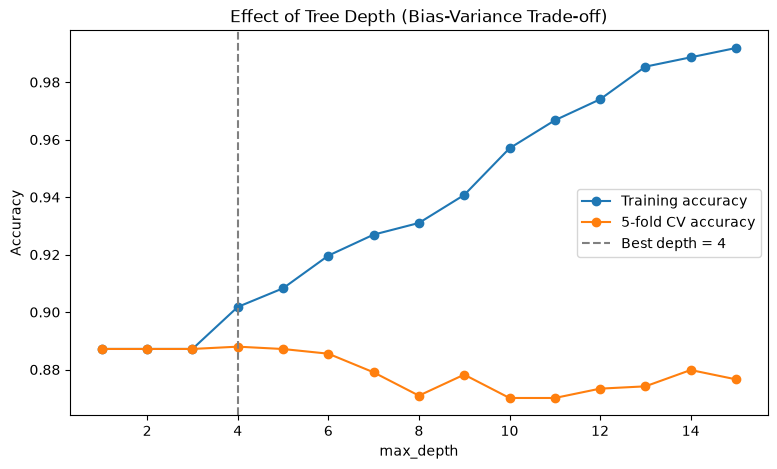

In [2]:
from sklearn.tree import DecisionTreeClassifier

depths = range(1, 16)
train_acc, cv_acc = [], []
for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=42)
    cv_acc.append(cross_val_score(tree, X_train, y_train, cv=cv).mean())
    train_acc.append(tree.fit(X_train, y_train).score(X_train, y_train))

best_depth = list(depths)[int(np.argmax(cv_acc))]
print("Best depth by CV:", best_depth, "| CV accuracy:", round(max(cv_acc), 4))

plt.figure(figsize=(9, 5))
plt.plot(depths, train_acc, marker="o", label="Training accuracy")
plt.plot(depths, cv_acc, marker="o", label="5-fold CV accuracy")
plt.axvline(best_depth, color="grey", linestyle="--", label=f"Best depth = {best_depth}")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Effect of Tree Depth (Bias-Variance Trade-off)")
plt.legend()
plt.show()

## Cost-Complexity Pruning

`cost_complexity_pruning_path` lists the alpha values at which branches of a fully
grown tree would be removed. Each alpha is scored with 5-fold CV.

Best ccp_alpha by CV: 0.00405


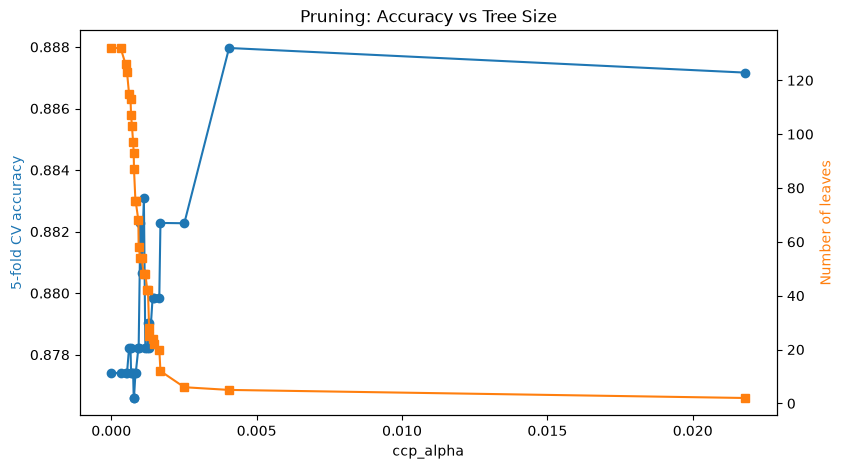

In [3]:
path = DecisionTreeClassifier(random_state=42).cost_complexity_pruning_path(X_train, y_train)
alphas = np.unique(np.round(path.ccp_alphas[:-1], 5))
alphas = alphas[np.linspace(0, len(alphas) - 1, min(30, len(alphas))).astype(int)]

prune = pd.DataFrame({
    "alpha": alphas,
    "CV accuracy": [cross_val_score(DecisionTreeClassifier(ccp_alpha=a, random_state=42),
                                    X_train, y_train, cv=cv).mean() for a in alphas],
    "Leaves": [DecisionTreeClassifier(ccp_alpha=a, random_state=42).fit(X_train, y_train).get_n_leaves() for a in alphas],
})
best_alpha = prune.loc[prune["CV accuracy"].idxmax(), "alpha"]
print("Best ccp_alpha by CV:", best_alpha)

fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(prune["alpha"], prune["CV accuracy"], marker="o", color="tab:blue")
ax1.set_xlabel("ccp_alpha")
ax1.set_ylabel("5-fold CV accuracy", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(prune["alpha"], prune["Leaves"], marker="s", color="tab:orange")
ax2.set_ylabel("Number of leaves", color="tab:orange")
plt.title("Pruning: Accuracy vs Tree Size")
plt.show()

## Final Tree on the Test Set

Test accuracy: 0.8669

              precision    recall  f1-score   support

    Not high       0.86      0.90      0.88       168
        High       0.87      0.83      0.85       140

    accuracy                           0.87       308
   macro avg       0.87      0.86      0.87       308
weighted avg       0.87      0.87      0.87       308



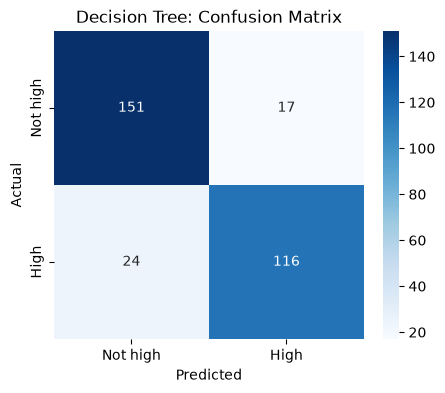

In [4]:
model = DecisionTreeClassifier(max_depth=best_depth, random_state=42).fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))
print()
print(classification_report(y_test, y_pred, target_names=["Not high", "High"]))

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not high", "High"], yticklabels=["Not high", "High"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree: Confusion Matrix")
plt.show()

**How to read these metrics**

- **Accuracy**: share of all test plots classified correctly.
- **Precision (High)**: of the plots predicted "high", how many really are high.
- **Recall (High)**: of the truly high plots, how many the model caught.
- **F1**: the balance of precision and recall.
- **Confusion matrix**: rows are the true class, columns the predicted class. The
  diagonal holds correct predictions; the off-diagonal cells are the two kinds of mistake.

## Visualising and Interpreting the Tree

A depth-3 tree is drawn because it is small enough to read; its rules are also printed
as text, and the feature importances (how much each feature reduces impurity across
all splits) are listed.

Depth-3 tree test accuracy: 0.8701


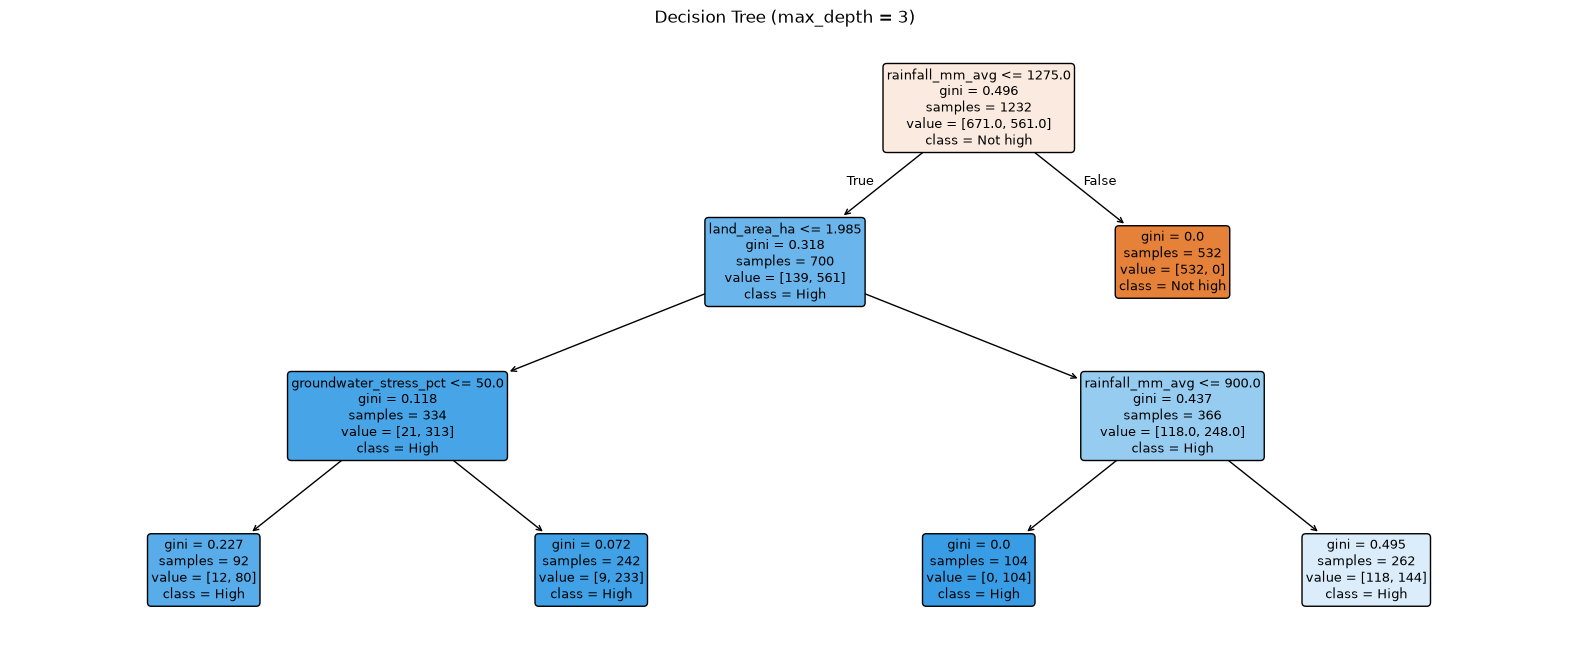

|--- rainfall_mm_avg <= 1275.00
|   |--- land_area_ha <= 1.99
|   |   |--- groundwater_stress_pct <= 50.00
|   |   |   |--- class: 1
|   |   |--- groundwater_stress_pct >  50.00
|   |   |   |--- class: 1
|   |--- land_area_ha >  1.99
|   |   |--- rainfall_mm_avg <= 900.00
|   |   |   |--- class: 1
|   |   |--- rainfall_mm_avg >  900.00
|   |   |   |--- class: 1
|--- rainfall_mm_avg >  1275.00
|   |--- class: 0



,Feature,Importance
3,rainfall_mm_avg,0.9221
4,land_area_ha,0.0571
6,claim_IFR,0.0174
2,groundwater_stress_pct,0.0026
1,soil_organic_carbon,0.0008
0,soil_ph,0.0000
5,claim_CR,0.0000


In [5]:
from sklearn.tree import plot_tree, export_text

small = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)
print("Depth-3 tree test accuracy:", round(small.score(X_test, y_test), 4))

plt.figure(figsize=(20, 8))
plot_tree(small, feature_names=list(X.columns), class_names=["Not high", "High"],
          filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree (max_depth = 3)")
plt.show()

print(export_text(small, feature_names=list(X.columns)))
pd.DataFrame({"Feature": X.columns, "Importance": model.feature_importances_.round(4)}).sort_values(by="Importance", ascending=False)

## Decision Tree Regression

Decision Trees can also predict numbers. Here a **Decision Tree Regressor** predicts
the `soil_health_card_score` from `soil_ph` and `soil_organic_carbon`. The Soil
Health Card rule is built from bands (acidic / neutral pH, low / medium / high organic
carbon), so its true shape is a set of steps; a tree, whose predictions are also
steps, is a natural fit. It is compared with Multiple Linear Regression, which can
only produce a flat, tilted surface.

Best regression-tree depth by CV: 3
Decision Tree Regressor - test R2: 0.9324
Linear Regression       - test R2: 0.4232


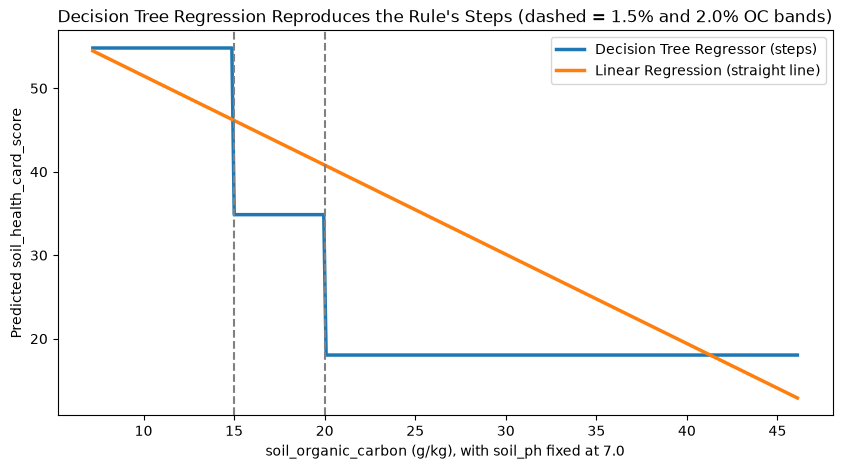

In [6]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score

Xr = df[["soil_ph", "soil_organic_carbon"]]
yr = df["soil_health_card_score"]
Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.2, random_state=42)
kf = KFold(5, shuffle=True, random_state=42)

reg_depths = range(1, 11)
reg_cv = [cross_val_score(DecisionTreeRegressor(max_depth=d, random_state=42), Xr_train, yr_train, cv=kf, scoring="r2").mean()
          for d in reg_depths]
best_reg_depth = list(reg_depths)[int(np.argmax(reg_cv))]
reg_tree = DecisionTreeRegressor(max_depth=best_reg_depth, random_state=42).fit(Xr_train, yr_train)
linear = LinearRegression().fit(Xr_train, yr_train)

print(f"Best regression-tree depth by CV: {best_reg_depth}")
print(f"Decision Tree Regressor - test R2: {r2_score(yr_test, reg_tree.predict(Xr_test)):.4f}")
print(f"Linear Regression       - test R2: {r2_score(yr_test, linear.predict(Xr_test)):.4f}")

oc_line = pd.DataFrame({"soil_ph": 7.0, "soil_organic_carbon": np.linspace(Xr.soil_organic_carbon.min(), Xr.soil_organic_carbon.max(), 300)})
plt.figure(figsize=(10, 5))
plt.plot(oc_line["soil_organic_carbon"], reg_tree.predict(oc_line), linewidth=2.5, label="Decision Tree Regressor (steps)")
plt.plot(oc_line["soil_organic_carbon"], linear.predict(oc_line), linewidth=2.5, label="Linear Regression (straight line)")
for cut in [15, 20]:
    plt.axvline(cut, color="grey", linestyle="--")
plt.xlabel("soil_organic_carbon (g/kg), with soil_ph fixed at 7.0")
plt.ylabel("Predicted soil_health_card_score")
plt.title("Decision Tree Regression Reproduces the Rule's Steps (dashed = 1.5% and 2.0% OC bands)")
plt.legend()
plt.show()

## Conclusion

**Classification tree**

| Setting | Value |
|---|---|
| Best depth (5-fold CV) | 4 (CV accuracy 0.888) |
| Best pruning alpha (5-fold CV) | 0.004 |
| Test accuracy, depth 4 | 0.867 |
| Test accuracy, depth 3 (drawn) | 0.870 |

1. **Depth:** training accuracy keeps rising with depth towards 100%, while CV accuracy
   peaks at depth 4 and then falls: deeper trees memorise noise (overfitting).
   Pruning with `ccp_alpha` shows the same trade-off from the other direction: the
   fully grown tree has 132 leaves, and pruning it to about 6 leaves loses no CV
   accuracy at all, so almost all of those extra leaves were fitting noise.
2. **Interpretation:** the tree relies almost entirely on rainfall (importance 0.92),
   then land area (0.06). The depth-3 tree effectively reduces to one rule:
   **rainfall ≤ 1,275 mm → high priority**, because every leaf under that split
   predicts "High". Rainfall is fixed per district, so the tree is mostly separating
   dry districts from wet ones, which is the strongest part of the PMKSY rule.
3. Trees are the easiest model to explain, but here they are slightly less accurate
   (0.867) than logistic regression, KNN or SVM (about 0.90), because a few threshold
   splits cannot use all the smaller effects at once.

**Regression tree**

| Model (soil pH + organic carbon) | Test R² |
|---|---|
| Decision Tree Regressor (depth 3, chosen by CV) | **0.932** |
| Linear Regression | 0.423 |

4. The Soil Health Card rule is built from bands, so its true shape is a set of steps.
   The regression tree reproduces those steps: in the plot its jumps fall at 15.0 and
   20.1 g/kg, which are exactly the rule's 1.5% and 2.0% organic-carbon bands, and it
   learned them only from the data. A linear model can only draw a tilted line through
   the steps. This is the main strength of trees: they fit threshold-based rules naturally.
